# 05 Feature Engineering: New Inputs and School Districts

**IDX Exchange Data Science Internship, Week 6 deliverable**

**Goal.** Add new inputs to the models, including a school-district layer built by locating each home on the official map of California school districts, retrain the three models (linear regression, decision tree, random forest), and compare the old and new input sets in one table.

**New inputs, added in four steps** so that each step's contribution can be measured:
1. **Age at sale and bedroom-to-bathroom ratio.** Age at sale (sale year minus year built) replaces year built, as the best-practices document recommends.
2. **Month of sale:** the month as a point on a circle (sine and cosine, so December and January are neighbors) and a count of months since January 2024, so a model can tell older sales from recent ones.
3. **School districts** from the California Department of Education's 2024-25 district boundaries.
4. **Nearby sales price per square foot:** the median price per square foot of the nearest sales in the training months (how many is chosen in Section 3), the comparable-sales idea used by appraisers and recommended by the best-practices document.

**Same rules as before.** Settings are chosen on the March 2026 validation month (training on March 2025 to February 2026); the test month, April 2026, is used once per model at the end (training on April 2025 to March 2026). Every model predicts log price. MdAPE (median percentage error) is the headline measure; R², MAPE and MAE are also reported.

**Two changes agreed in Week 5:**
- Settings are chosen with the **one-standard-error rule**: among settings whose validation MdAPE is within one standard error of the best, the simplest is taken. The standard error of each gap comes from a paired bootstrap over the validation homes.
- The stability check uses **all twelve months of 2025** plus the test month, instead of three hand-picked months.

**Contents**
1. Load the data and build the new inputs
2. The new inputs at a glance
3. Choosing the number of nearby sales
4. Comparing input sets on the validation month
5. Rechecking the 12-month training window
6. The test month: old against new inputs
7. Stability over all of 2025
8. Where the new inputs help
9. Saved results
10. Summary and next steps

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

ROOT = next(p for p in [Path('..'), Path('.')] if (p / 'src' / 'preprocessing.py').exists()).resolve()
sys.path.insert(0, str(ROOT))
import src.preprocessing as prep
import src.modeling as mdl
import src.features as feat

SEED = prep.set_global_seed()
print('Random seed:', SEED)

CONFIG = json.loads((ROOT / 'config' / 'split_config.json').read_text())
RESULTS_DIR = ROOT / 'results'
FIG_DIR = ROOT / 'reports' / 'figures'
N_MONTHS = CONFIG['n_train_months']
TEST_MONTH = CONFIG['final']['test_month']
VALIDATION_MONTH = CONFIG['tuning']['validation_month']

MODEL_COLORS = {'Linear regression': '#2a78d6', 'Decision tree': '#eb6834', 'Random forest': '#1baf7a'}
SET_COLORS = ['#a3a29d', '#2a78d6', '#eb6834', '#4a3aa7', '#1baf7a']
LIGHT_GRAY = '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c9c8c3', 'axes.linewidth': 0.8, 'axes.grid': True,
    'grid.color': LIGHT_GRAY, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'font.size': 9.5,
})
pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')


def save_fig(name):
    plt.savefig(FIG_DIR / f'{name}.png', dpi=130, bbox_inches='tight')


def money(x, _=None):
    return f'${x / 1e6:.1f}M' if abs(x) >= 1e6 else f'${x / 1e3:.0f}K'


def pct_axis(ax, decimals=1):
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:.{decimals}f}%'))

Random seed: 42


## 1. Load the data and build the new inputs

All new inputs except the nearby-sales one are computed from each home's own record or from the fixed district map, so they are added to every month before splitting. The nearby-sales input depends on other homes' prices, so it is computed inside the fitted model pipeline from training sales only (Section 3 explains how).

In [2]:
clean_df = prep.load_clean(ROOT / 'data' / 'processed' / 'sfr_clean.csv')
data = feat.add_all_features(clean_df)

train_tune, val_tune, _ = prep.make_split(data, VALIDATION_MONTH, N_MONTHS)
train_final, test_final, _ = prep.make_split(data, TEST_MONTH, N_MONTHS)
assert len(train_final) == CONFIG['final']['train_rows'] and len(test_final) == CONFIG['final']['test_rows']
print(f'{len(data):,} sales; settings split {len(train_tune):,} / {len(val_tune):,}; '
      f'final split {len(train_final):,} / {len(test_final):,}')

pd.DataFrame({name: {'inputs': len(cols), 'added': ', '.join(c for c in cols if c not in prev) or '(Week 3 set)'}
              for (name, cols), prev in zip(feat.FEATURE_SETS.items(), [[]] + list(feat.FEATURE_SETS.values())[:-1])}).T

308,862 sales; settings split 127,358 / 11,354; final split 128,330 / 12,268


,inputs,added
Original (Week 3),17,"LivingArea, LotSizeSquareFeet, BedroomsTotal, BathroomsTotalInteger, YearBui..."
"+ age, bed/bath ratio",18,"AgeAtSale, BedBathRatio"
+ month of sale,21,"SaleMonthSin, SaleMonthCos, SaleMonthIndex"
+ school districts,23,"SchoolDistrictElem, SchoolDistrictHigh"
+ nearby sales price per sq ft,24,NearbyPricePerSqft


## 2. The new inputs at a glance

**Age, bed/bath ratio and month of sale.**

In [3]:
new_numeric = prep.ENGINEERED_FEATURES + prep.TIME_FEATURES
summary = data[new_numeric].describe(percentiles=[.25, .5, .75]).T[['count', 'mean', 'min', '25%', '50%', '75%', 'max']]
summary['missing %'] = 100 * data[new_numeric].isna().mean()
summary

,count,mean,min,25%,50%,75%,max,missing %
AgeAtSale,"308,677.00",49.03,0.00,27.00,49.00,69.00,172.00,0.06
BedBathRatio,"308,661.00",1.46,0.25,1.00,1.50,1.50,7.50,0.07
SaleMonthSin,"308,862.00",0.09,-1.00,-0.50,0.00,0.87,1.00,0.00
SaleMonthCos,"308,862.00",-0.04,-1.00,-0.50,-0.00,0.50,1.00,0.00
SaleMonthIndex,"308,862.00",13.30,0.00,6.00,13.00,20.00,27.00,0.00


**School districts.** The state map combines three kinds of districts: *unified* districts cover all grades, while elsewhere separate *elementary* and *high-school* districts overlap the same land. Each home therefore gets two inputs: its unified district if it has one, otherwise its elementary district (`SchoolDistrictElem`), and its unified district if it has one, otherwise its high-school district (`SchoolDistrictHigh`). Like ZIP code, each district is turned into one number, the average log sale price of training homes in that district, computed so that a home's own price never contributes to its own value.

The map file also carries district demographics (shares of students by race and ethnicity, and of disadvantaged students). **These are deliberately not used.** Feeding the demographic make-up of a neighborhood into a home-price model is a recognized fair-housing problem for valuation models, and the task asks for the district as a regional feature, not for its demographics.

In [4]:
districts = feat.load_school_districts()
coverage = pd.Series({
    'districts on the map': len(districts),
    'of which unified / elementary / high': ' / '.join(str(int((districts['DistrictType'] == t).sum()))
                                                    for t in ['Unified', 'Elementary', 'High']),
    'homes matched to a district': f"{data['SchoolDistrictElem'].notna().mean():.2%}",
    'homes without coordinates': f"{data['Latitude'].isna().mean():.2%}",
    'homes with coordinates but outside every district': int((data['SchoolDistrictElem'].isna() & data['Latitude'].notna()).sum()),
    'distinct districts among the homes (elementary input / high input)':
        f"{data['SchoolDistrictElem'].nunique()} / {data['SchoolDistrictHigh'].nunique()}",
    'distinct ZIP codes among the homes': data['ZIP5'].nunique(),
})
coverage.to_frame('value')

,value
districts on the map,937
of which unified / elementary / high,345 / 516 / 76
homes matched to a district,99.10%
homes without coordinates,0.89%
homes with coordinates but outside every district,27
distinct districts among the homes (elementary input / high input),686 / 404
distinct ZIP codes among the homes,1567


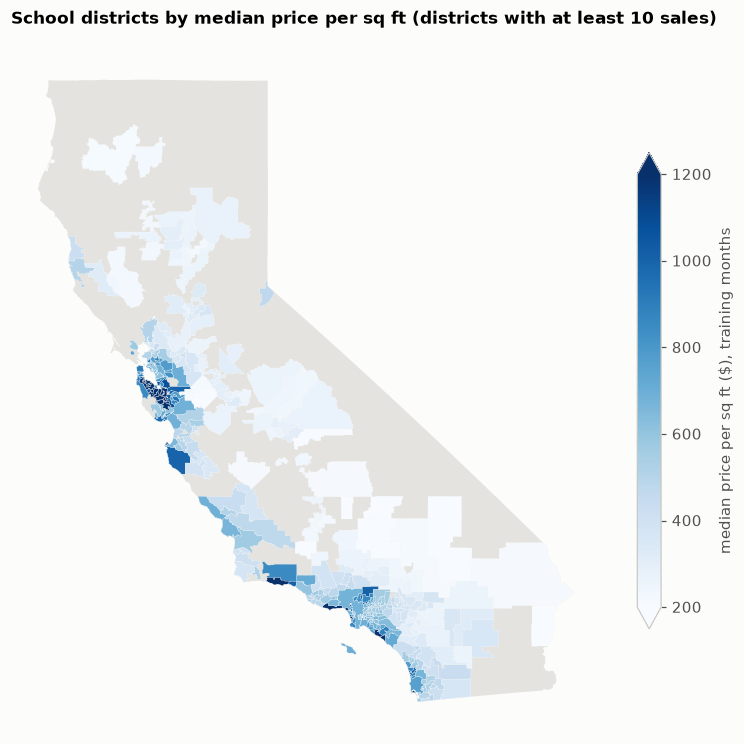

In [5]:
# Median price per sq ft of the final training months, by district (elementary input)
ppsf = (train_final[prep.TARGET] / train_final['LivingArea']).groupby(train_final['SchoolDistrictElem']).agg(['median', 'size'])
shown = districts[districts['DistrictType'] != 'High'].merge(ppsf[ppsf['size'] >= 10], left_on='CDSCode', right_index=True)
ca = districts.dissolve()

fig, ax = plt.subplots(figsize=(7, 7.5))
ca.plot(ax=ax, color=LIGHT_GRAY, edgecolor='none')
shown.plot(ax=ax, column='median', cmap='Blues', vmin=200, vmax=1200, edgecolor='#ffffff', linewidth=0.15,
           legend=True, legend_kwds={'label': 'median price per sq ft ($), training months', 'shrink': 0.6})
ax.set_axis_off()
ax.set_title('School districts by median price per sq ft (districts with at least 10 sales)')
plt.tight_layout()
save_fig('05_district_map')
plt.show()

## 3. Choosing the number of nearby sales

**How the input works.** For a home, take the k training sales closest to it (by distance on the map) and compute the median of their log price per square foot. This is close to how an appraiser uses comparable sales: what similar homes nearby sold for, per square foot. It differs from the ZIP-code input in that it follows each home's own neighborhood instead of a fixed boundary.

**Keeping it honest.** The input is computed inside the model pipeline. When the model is trained, each training home's value comes from the *other* training homes near it, never from its own sale; homes in the validation or test month use the training sales only. A unit check confirmed that a training home is excluded from its own neighbors, even when another home sits at identical coordinates.

**Choosing k.** Smaller k follows the local neighborhood more closely but is noisier; larger k is smoother. Several values are tried with the random forest on the full new input set, and the one-standard-error rule picks the largest k (the smoothest) that is statistically tied with the best.

In [6]:
RF_DEFAULT = dict(n_estimators=300, max_features=0.33, min_samples_leaf=1)
y_val = val_tune[prep.TARGET].to_numpy()
full = feat.WITH_NEARBY
cols_full = prep.input_columns(full)

k_preds = {}
for k in [5, 10, 25, 50, 100]:
    model = mdl.price_model(RandomForestRegressor(**RF_DEFAULT, n_jobs=-1, random_state=SEED), features=full, nearby_k=k)
    k_preds[k] = model.fit(train_tune[cols_full], train_tune[prep.TARGET]).predict(val_tune[cols_full])
NEARBY_K, k_table = mdl.one_se_select(y_val, k_preds, complexity={k: 1 / k for k in k_preds})
print('Chosen number of nearby sales: k =', NEARBY_K)
k_table[['MdAPE', 'gap_to_best', 'se_of_gap', 'within_1se']].round(3)

Chosen number of nearby sales: k = 100


,MdAPE,gap_to_best,se_of_gap,within_1se
setting,,,,
5,7.72,0.19,0.07,False
10,7.61,0.08,0.06,False
25,7.59,0.07,0.05,False
50,7.53,0.00,0.00,True
100,7.55,0.02,0.05,True


## 4. Comparing input sets on the validation month

For each of the five input sets, each model's settings are chosen on the validation month with the one-standard-error rule:
- **Decision tree:** maximum depth and minimum leaf size; simpler means fewer leaves.
- **Random forest:** share of inputs per split and minimum leaf size, with 300 trees; simpler means fewer tree nodes in total.
- **Linear regression:** no settings.

In [7]:
DT_GRID = [(d, l) for d in [10, 12, 14, 16, 20, None] for l in [5, 10, 20, 50]]
RF_GRID = [(mf, l) for mf in [0.2, 0.33, 0.5, 0.75] for l in [1, 2, 5]]


def fit_predict(estimator, features, train, evaluation):
    cols = prep.input_columns(features)
    model = mdl.price_model(estimator, features=features, nearby_k=NEARBY_K).fit(train[cols], train[prep.TARGET])
    return model, model.predict(evaluation[cols])


chosen, val_rows, tuning_rows = {}, [], []
start = time.time()
for set_name, features in feat.FEATURE_SETS.items():
    _, p = fit_predict(LinearRegression(), features, train_tune, val_tune)
    chosen[(set_name, 'Linear regression')] = {}
    val_rows.append({'feature set': set_name, 'model': 'Linear regression', 'settings': '-',
                     **prep.regression_metrics(y_val, p)})

    preds, complexity = {}, {}
    for depth, leaf in DT_GRID:
        m, preds[(depth, leaf)] = fit_predict(DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=SEED),
                                              features, train_tune, val_tune)
        complexity[(depth, leaf)] = m.regressor_.named_steps['model'].get_n_leaves()
    key, table = mdl.one_se_select(y_val, preds, complexity)
    chosen[(set_name, 'Decision tree')] = {'max_depth': key[0], 'min_samples_leaf': key[1]}
    val_rows.append({'feature set': set_name, 'model': 'Decision tree', 'settings': f'depth {key[0]}, leaf {key[1]}',
                     **prep.regression_metrics(y_val, preds[key])})
    tuning_rows += [{'feature set': set_name, 'model': 'Decision tree', 'setting': f'depth {k[0]}, leaf {k[1]}', **r}
                    for k, r in table.to_dict('index').items()]

    preds, complexity = {}, {}
    for mf, leaf in RF_GRID:
        m, preds[(mf, leaf)] = fit_predict(RandomForestRegressor(n_estimators=300, max_features=mf, min_samples_leaf=leaf,
                                                                 n_jobs=-1, random_state=SEED), features, train_tune, val_tune)
        complexity[(mf, leaf)] = sum(t.tree_.node_count for t in m.regressor_.named_steps['model'].estimators_)
    key, table = mdl.one_se_select(y_val, preds, complexity)
    chosen[(set_name, 'Random forest')] = {'n_estimators': 300, 'max_features': key[0], 'min_samples_leaf': key[1]}
    val_rows.append({'feature set': set_name, 'model': 'Random forest', 'settings': f'{key[0]} of inputs, leaf {key[1]}',
                     **prep.regression_metrics(y_val, preds[key])})
    tuning_rows += [{'feature set': set_name, 'model': 'Random forest', 'setting': f'{k[0]} of inputs, leaf {k[1]}', **r}
                    for k, r in table.to_dict('index').items()]
    print(f'{set_name}: done ({time.time() - start:.0f} s)', flush=True)

validation = pd.DataFrame(val_rows)
tuning = pd.DataFrame(tuning_rows)
validation.pivot(index='feature set', columns='model', values='MdAPE').loc[list(feat.FEATURE_SETS)].round(2)

Original (Week 3): done (104 s)


+ age, bed/bath ratio: done (212 s)


+ month of sale: done (329 s)


+ school districts: done (461 s)


+ nearby sales price per sq ft: done (1212 s)


model,Decision tree,Linear regression,Random forest
feature set,,,
Original (Week 3),9.63,11.40,7.73
"+ age, bed/bath ratio",9.69,11.27,7.72
+ month of sale,9.79,11.25,7.88
+ school districts,9.68,11.06,7.75
+ nearby sales price per sq ft,9.55,9.51,7.49


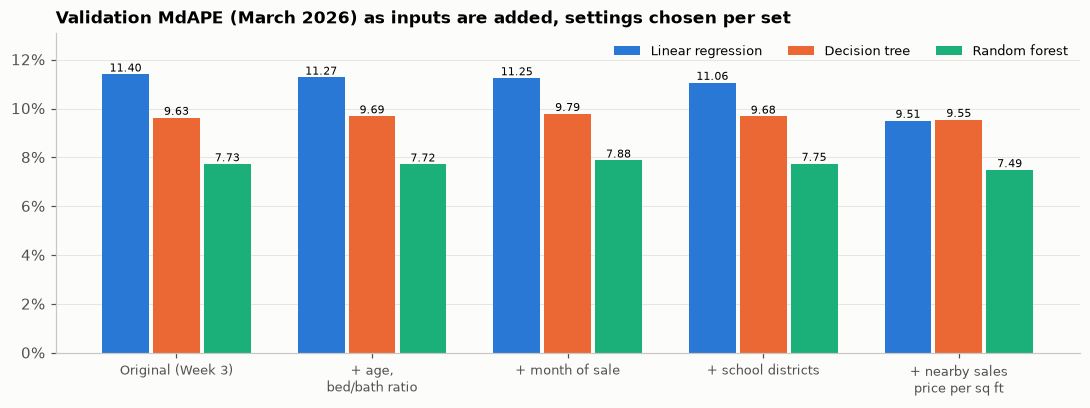

model,Decision tree,Linear regression,Random forest
feature set,,,
Original (Week 3),"depth 16, leaf 10",-,"0.33 of inputs, leaf 2"
"+ age, bed/bath ratio","depth 16, leaf 10",-,"0.5 of inputs, leaf 2"
+ month of sale,"depth 16, leaf 10",-,"0.33 of inputs, leaf 2"
+ school districts,"depth 20, leaf 20",-,"0.33 of inputs, leaf 2"
+ nearby sales price per sq ft,"depth 14, leaf 20",-,"0.2 of inputs, leaf 2"


In [8]:
fig, ax = plt.subplots(figsize=(10, 3.8))
sets = list(feat.FEATURE_SETS)
width = 0.26
for k, model_name in enumerate(MODEL_COLORS):
    v = validation[validation['model'] == model_name].set_index('feature set').loc[sets, 'MdAPE']
    bars = ax.bar(np.arange(len(sets)) + (k - 1) * width, v, width=width * 0.92, color=MODEL_COLORS[model_name], label=model_name)
    for b, val in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, val, f'{val:.2f}', ha='center', va='bottom', fontsize=7.5)
ax.set_xticks(range(len(sets)), [s.replace(', ', ',\n').replace(' price', '\nprice') for s in sets], fontsize=8.5)
ax.set_ylim(0, validation['MdAPE'].max() * 1.15)
pct_axis(ax, 0)
ax.set_title('Validation MdAPE (March 2026) as inputs are added, settings chosen per set')
ax.legend(frameon=False, fontsize=8.5, ncol=3, loc='upper right')
ax.grid(axis='x', visible=False)
plt.tight_layout()
save_fig('05_validation_by_set')
plt.show()

validation.pivot(index='feature set', columns='model', values='settings').loc[sets]

## 5. Rechecking the 12-month training window

In Week 3 the window was set to 12 months, partly because the models had no input describing when a sale happened, so older months added stale prices. The new set includes the month of sale, so a longer window may now help. The Week 3 procedure is repeated with the full new input set: for each window length, train on the months before each of the three validation months (January, February, March 2026), and pool the three months' predictions. The one-standard-error rule then picks the shortest window that is statistically tied with the best.

In [9]:
WINDOWS = [6, 9, 12, 18, 24]
WINDOW_MONTHS = ['2026-01', '2026-02', '2026-03']
rf_full_settings = chosen[('+ nearby sales price per sq ft', 'Random forest')]
# Each window computes its own outlier cutoffs, so the evaluated months keep slightly different
# homes per window. Windows are compared on the homes kept under every window (a paired comparison).
raw_preds = {}
for x in WINDOWS:
    for month in WINDOW_MONTHS:
        tr, ev, _ = prep.make_split(data, month, x)
        p_lr = fit_predict(LinearRegression(), full, tr, ev)[1]
        p_rf = fit_predict(RandomForestRegressor(**rf_full_settings, n_jobs=-1, random_state=SEED), full, tr, ev)[1]
        raw_preds[(x, month)] = pd.DataFrame({'y': ev[prep.TARGET].to_numpy(), 'Linear regression': p_lr,
                                              'Random forest': p_rf}, index=ev['ListingKey'].to_numpy())
common = {m: set.intersection(*(set(raw_preds[(x, m)].index) for x in WINDOWS)) for m in WINDOW_MONTHS}
order = {m: sorted(common[m]) for m in WINDOW_MONTHS}
y_pool = np.concatenate([raw_preds[(WINDOWS[0], m)].loc[order[m], 'y'].to_numpy() for m in WINDOW_MONTHS])
window_preds = {name: {x: np.concatenate([raw_preds[(x, m)].loc[order[m], name].to_numpy() for m in WINDOW_MONTHS])
                       for x in WINDOWS} for name in ['Linear regression', 'Random forest']}
print(f'Homes compared across all windows: {len(y_pool):,} (Jan to Mar 2026 pooled)')

window_tables = {}
for model_name, preds in window_preds.items():
    sel, table = mdl.one_se_select(y_pool, preds, complexity={x: x for x in WINDOWS})
    window_tables[model_name] = (sel, table)
    print(f'{model_name}: best window {table["MdAPE"].idxmin()} months, one-SE choice {sel} months')
pd.concat({m: t[['MdAPE', 'gap_to_best', 'se_of_gap', 'within_1se']] for m, (_, t) in window_tables.items()}, axis=1).round(3)

Homes compared across all windows: 27,481 (Jan to Mar 2026 pooled)


Linear regression: best window 18 months, one-SE choice 18 months


Random forest: best window 24 months, one-SE choice 24 months


Linear regression                                  Random forest                                 
                    MdAPE gap_to_best se_of_gap within_1se         MdAPE gap_to_best se_of_gap within_1se
setting                                                                                                  
6                    9.86        0.27      0.06      False          7.98        0.55      0.05      False
9                    9.72        0.14      0.04      False          7.79        0.36      0.04      False
12                   9.63        0.04      0.04      False          7.59        0.16      0.04      False
18                   9.59        0.00      0.00       True          7.55        0.11      0.03      False
24                   9.60        0.02      0.04       True          7.43        0.00      0.00       True

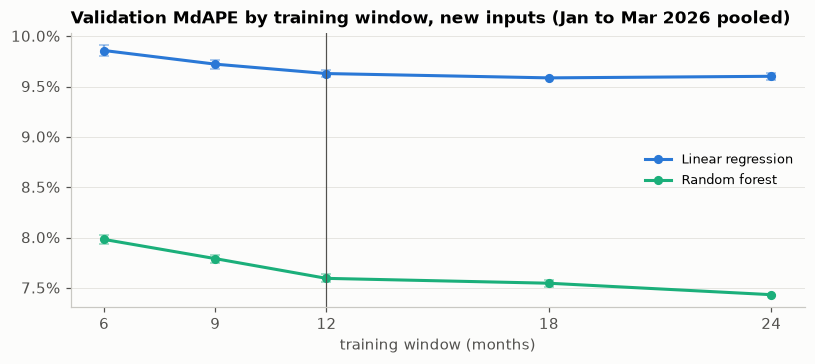

One-SE window choice per model: {'Linear regression': np.int64(18), 'Random forest': np.int64(24)}
The old-vs-new comparison (Section 6) and the stability check (Section 7) keep the 12-month window, so they stay comparable with Weeks 4 and 5; a different window choice is scored separately in Section 6.


In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for model_name, (sel, table) in window_tables.items():
    ax.plot(table.index, table['MdAPE'], color=MODEL_COLORS[model_name], lw=2, marker='o', ms=5, label=model_name)
    ax.errorbar(table.index, table['MdAPE'], yerr=table['se_of_gap'], fmt='none', ecolor=MODEL_COLORS[model_name], alpha=0.5, capsize=3)
ax.axvline(12, color='#52514e', lw=0.8)
ax.set_xticks(WINDOWS)
ax.set_xlabel('training window (months)')
pct_axis(ax, 1)
ax.set_title('Validation MdAPE by training window, new inputs (Jan to Mar 2026 pooled)')
ax.legend(frameon=False, fontsize=8.5)
ax.grid(axis='x', visible=False)
plt.tight_layout()
save_fig('05_window_check')
plt.show()

WINDOW_CHOICE = {m: sel for m, (sel, _) in window_tables.items()}
print('One-SE window choice per model:', WINDOW_CHOICE)
print(f'The old-vs-new comparison (Section 6) and the stability check (Section 7) keep the {N_MONTHS}-month window, '
      'so they stay comparable with Weeks 4 and 5; a different window choice is scored separately in Section 6.')

## 6. The test month: old against new inputs

Every input set is now trained with its chosen settings on the final 12 training months (April 2025 to March 2026) and scored once on April 2026. This is the deliverable table comparing the old and new input sets; the window stays at 12 months so the comparison matches Weeks 4 and 5.

In [11]:
MODELS = {
    'Linear regression': lambda s: LinearRegression(),
    'Decision tree': lambda s: DecisionTreeRegressor(**chosen[(s, 'Decision tree')], random_state=SEED),
    'Random forest': lambda s: RandomForestRegressor(**chosen[(s, 'Random forest')], n_jobs=-1, random_state=SEED),
}
train_x, test_x, _ = prep.make_split(data, TEST_MONTH, N_MONTHS)
y_test = test_x[prep.TARGET].to_numpy()
test_rows, test_preds = [], {}
for set_name, features in feat.FEATURE_SETS.items():
    for model_name, make in MODELS.items():
        _, p = fit_predict(make(set_name), features, train_x, test_x)
        test_preds[(set_name, model_name)] = p
        test_rows.append({'feature set': set_name, 'model': model_name, **prep.regression_metrics(y_test, p),
                          'within 10%': 100 * np.mean(np.abs(p - y_test) / y_test <= 0.10)})
test_results = pd.DataFrame(test_rows)

def show(df):
    out = df.copy()
    out['R2'] = out['R2'].map('{:.3f}'.format)
    for c in ['MAPE', 'MdAPE', 'within 10%']:
        out[c] = out[c].map('{:.2f}%'.format)
    out['MAE'] = out['MAE'].map('${:,.0f}'.format)
    return out

show(test_results).set_index(['model', 'feature set'])[['R2', 'MAPE', 'MdAPE', 'MAE', 'within 10%']]

,,R2,MAPE,MdAPE,MAE,within 10%
model,feature set,,,,,
Linear regression,Original (Week 3),0.820,15.17%,11.38%,"$207,051",44.66%
Decision tree,Original (Week 3),0.844,14.21%,9.83%,"$194,805",50.68%
Random forest,Original (Week 3),0.884,11.46%,7.74%,"$159,868",59.53%
Linear regression,"+ age, bed/bath ratio",0.823,15.09%,11.37%,"$206,112",45.21%
Decision tree,"+ age, bed/bath ratio",0.843,14.19%,9.90%,"$194,770",50.45%
Random forest,"+ age, bed/bath ratio",0.884,11.53%,7.76%,"$160,498",59.20%
Linear regression,+ month of sale,0.825,15.16%,11.25%,"$205,661",45.06%
Decision tree,+ month of sale,0.844,14.31%,10.01%,"$195,508",49.98%
Random forest,+ month of sale,0.883,11.60%,7.83%,"$161,360",59.40%


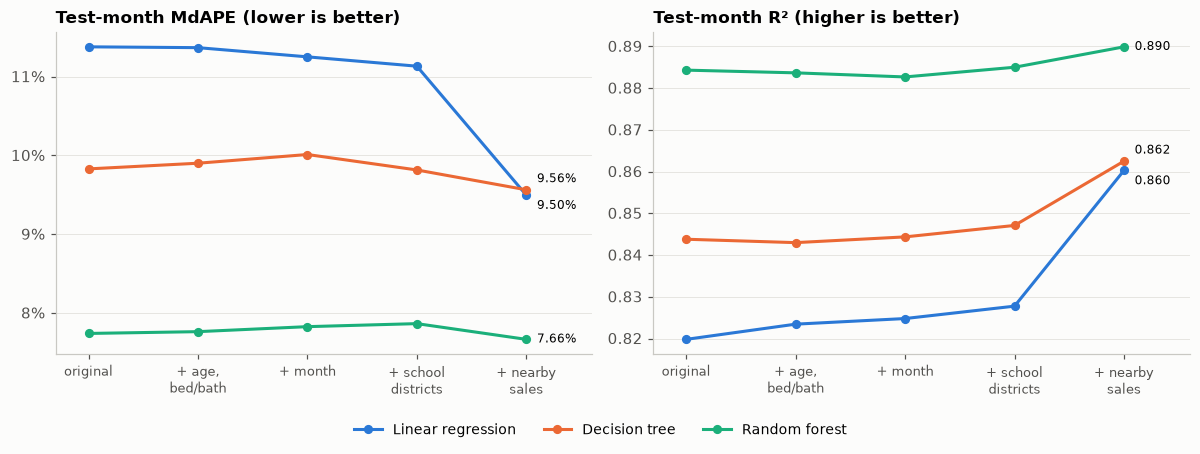

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1))
end_offset = {'Linear regression': -7, 'Decision tree': 7, 'Random forest': 0}   # keep close end labels apart
for ax, col, title in [(axes[0], 'MdAPE', 'Test-month MdAPE (lower is better)'), (axes[1], 'R2', 'Test-month R² (higher is better)')]:
    for k, model_name in enumerate(MODEL_COLORS):
        v = test_results[test_results['model'] == model_name].set_index('feature set').loc[sets, col]
        ax.plot(range(len(sets)), v, color=MODEL_COLORS[model_name], lw=2, marker='o', ms=5, label=model_name)
        ax.annotate(f'{v.iloc[-1]:.2f}%' if col == 'MdAPE' else f'{v.iloc[-1]:.3f}', (len(sets) - 1, v.iloc[-1]),
                    xytext=(7, end_offset[model_name] if col == 'MdAPE' else -end_offset[model_name] if model_name == 'Random forest' else (7 if v.iloc[-1] == max(t.iloc[-1] for t in [test_results[(test_results['model'] == m)].set_index('feature set').loc[sets, col] for m in ['Linear regression', 'Decision tree']]) else -7)), textcoords='offset points',
                    va='center', fontsize=8)
    ax.set_xticks(range(len(sets)), ['original', '+ age,\nbed/bath', '+ month', '+ school\ndistricts', '+ nearby\nsales'], fontsize=8.5)
    ax.set_xlim(-0.3, len(sets) - 0.4)
    ax.set_title(title)
    ax.grid(axis='x', visible=False)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))
pct_axis(axes[0], 0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.07, 1, 1))
save_fig('05_test_by_set')
plt.show()

**Is the gain from the new inputs real?** As in Week 5, the test homes are redrawn at random 2,000 times and the difference in MdAPE between the original and the full new input set is recomputed, for each model, with both versions scored on the same homes.

In [13]:
first, last = sets[0], sets[-1]
boot = pd.DataFrame([{'model': m, **mdl.bootstrap_mdape_difference(y_test, test_preds[(first, m)], test_preds[(last, m)])}
                     for m in MODELS]).set_index('model')
boot.columns = ['MdAPE gain (points)', '95% range low', '95% range high']
boot.round(2)

,MdAPE gain (points),95% range low,95% range high
model,,,
Linear regression,1.88,1.65,2.14
Decision tree,0.27,0.02,0.52
Random forest,0.08,-0.07,0.21


**Follow-up: the window chosen in Section 5.** Where the window recheck chose a length other than 12 months for a model, that model is also trained on the new input set with its chosen window (the months right before April 2026) and scored once on the test month. This row is reported separately because its training months differ from every other row.

In [14]:
followup_rows = []
for model_name, x in WINDOW_CHOICE.items():
    if x == N_MONTHS:
        continue
    tr_w, te_w, _ = prep.make_split(data, TEST_MONTH, x)
    _, p = fit_predict(MODELS[model_name](last), full, tr_w, te_w)
    y_w = te_w[prep.TARGET].to_numpy()
    followup_rows.append({'model': model_name, 'training window': f'{x} months ({tr_w.CloseMonth.min()} to {tr_w.CloseMonth.max()})',
                          **prep.regression_metrics(y_w, p), 'within 10%': 100 * np.mean(np.abs(p - y_w) / y_w <= 0.10),
                          'test homes': len(te_w)})
    twelve = test_results[(test_results['model'] == model_name) & (test_results['feature set'] == last)].iloc[0]
    followup_rows.append({'model': model_name, 'training window': f'{N_MONTHS} months (for comparison)',
                          **{k: twelve[k] for k in ['R2', 'MAPE', 'MdAPE', 'MAE', 'within 10%']}, 'test homes': len(test_x)})
followup = pd.DataFrame(followup_rows)
if followup.empty:
    print('Every model kept the 12-month window; no follow-up needed.')
else:
    display(show(followup).set_index(['model', 'training window']))

R2    MAPE  MdAPE       MAE within 10%  test homes
model             training window                                                                      
Linear regression 18 months (2024-10 to 2026-03)  0.864  13.16%  9.45%  $176,539     52.21%       12256
                  12 months (for comparison)      0.860  13.26%  9.50%  $178,117     52.15%       12268
Random forest     24 months (2024-04 to 2026-03)  0.900  10.81%  7.40%  $148,862     61.41%       12248
                  12 months (for comparison)      0.890  11.20%  7.66%  $155,195     60.60%       12268

## 7. Stability over all of 2025

The original and the full new input sets are compared at every month of 2025 and at the test month: for each month, train on the months before it (same window) and score that month. The linear regression and the random forest are shown. (The settings were chosen on March 2026 and are reused for the earlier months, a limitation noted in Week 5.)

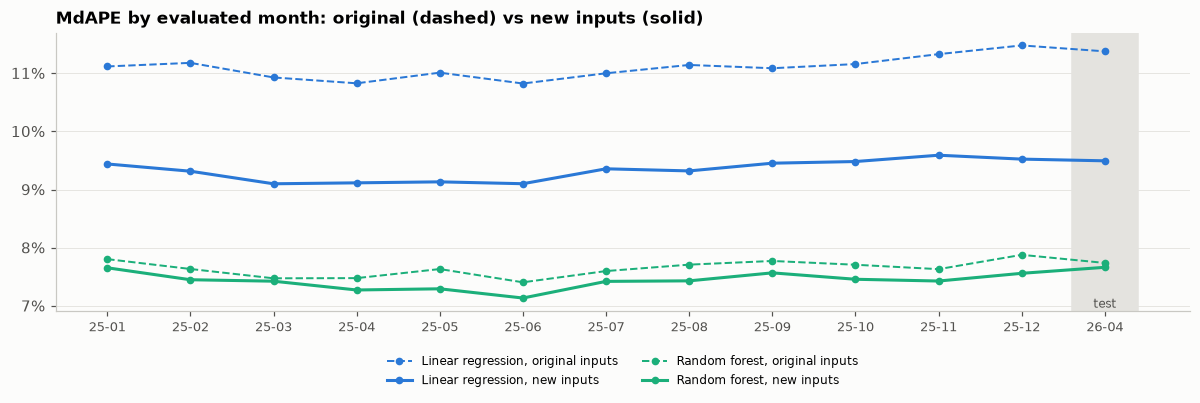

model                    Linear regression                                    Random forest                  
feature set + nearby sales price per sq ft Original (Week 3) + nearby sales price per sq ft Original (Week 3)
eval_month                                                                                                   
2025-01                               9.44             11.12                           7.66              7.81
2025-02                               9.32             11.18                           7.45              7.64
2025-03                               9.10             10.93                           7.43              7.48
2025-04                               9.12             10.83                           7.27              7.48
2025-05                               9.13             11.01                           7.30              7.63
2025-06                               9.10             10.82                           7.14              7.41
2025-07                               9.36             11.00                           7.42              7.60
2025-08                               9.32             11.14                           7.43              7.71
2025-09                               9.45             11.09                           7.57              7.77
2025-10                               9.48             11.16                           7.46              7.71
2025-11                               9.59             11.33                           7.43              7.63
2025-12                               9.53             11.48                           7.56              7.88
2026-04                               9.50             11.38                           7.66              7.74

In [15]:
STABILITY_MONTHS = [f'2025-{m:02d}' for m in range(1, 13)] + [TEST_MONTH]
stab_rows = []
for set_name in [first, last]:
    for model_name in ['Linear regression', 'Random forest']:
        for month in STABILITY_MONTHS:
            model, _, ev, r = mdl.fit_and_score(data, month, N_MONTHS, lambda: MODELS[model_name](set_name),
                                                features=feat.FEATURE_SETS[set_name], nearby_k=NEARBY_K)
            y = ev[prep.TARGET].to_numpy()
            p = model.predict(ev[prep.input_columns(feat.FEATURE_SETS[set_name])])
            stab_rows.append({'feature set': set_name, 'model': model_name, **r,
                              'median_signed_error': 100 * np.median((p - y) / y)})
stability = pd.DataFrame(stab_rows)

fig, ax = plt.subplots(figsize=(11, 3.8))
for model_name in ['Linear regression', 'Random forest']:
    for set_name, style in [(first, '--'), (last, '-')]:
        s = stability[(stability['model'] == model_name) & (stability['feature set'] == set_name)]
        ax.plot(s['eval_month'], s['MdAPE'], style, color=MODEL_COLORS[model_name], lw=2 if style == '-' else 1.3,
                marker='o', ms=4, label=f'{model_name}, {"new inputs" if set_name == last else "original inputs"}')
ax.axvspan(len(STABILITY_MONTHS) - 1.4, len(STABILITY_MONTHS) - 0.6, color=LIGHT_GRAY, zorder=0)
ax.text(len(STABILITY_MONTHS) - 1, ax.get_ylim()[0], 'test', ha='center', va='bottom', fontsize=8, color='#52514e')
ax.set_xticks(range(len(STABILITY_MONTHS)), [m[2:] for m in STABILITY_MONTHS], fontsize=8.5)
pct_axis(ax, 0)
ax.set_title('MdAPE by evaluated month: original (dashed) vs new inputs (solid)')
ax.legend(frameon=False, fontsize=8, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.grid(axis='x', visible=False)
plt.tight_layout()
save_fig('05_stability')
plt.show()

stab_view = stability.pivot_table(index='eval_month', columns=['model', 'feature set'], values='MdAPE').round(2)
stab_view

In [16]:
gain_by_month = pd.DataFrame({m: stability[(stability['model'] == m) & (stability['feature set'] == first)].set_index('eval_month')['MdAPE']
                                 - stability[(stability['model'] == m) & (stability['feature set'] == last)].set_index('eval_month')['MdAPE']
                              for m in ['Linear regression', 'Random forest']})
summary_stab = pd.DataFrame({
    'months where new inputs are better': (gain_by_month > 0).sum(),
    'mean gain (points)': gain_by_month.mean(),
    'smallest gain': gain_by_month.min(),
    'largest gain': gain_by_month.max(),
})
summary_stab.round(2)

,months where new inputs are better,mean gain (points),smallest gain,largest gain
Linear regression,13,1.77,1.63,1.95
Random forest,13,0.21,0.05,0.34


## 8. Where the new inputs help

**By price band.** The test homes are split into five groups of nearly equal size by sale price, as in Weeks 4 and 5. The expensive fifth (Q5) has been the weak spot of every model so far.

In [17]:
bands = pd.qcut(y_test, 5, labels=[f'Q{i}' for i in range(1, 6)])
edges = pd.Series(y_test).groupby(bands, observed=True).agg(['min', 'max'])
band = pd.DataFrame({'price range': [f'{money(a)} to {money(b)}' for a, b in edges.to_numpy()]}, index=edges.index)
for set_name, label in [(first, 'original'), (last, 'new')]:
    t = mdl.error_by_group(y_test, test_preds[(set_name, 'Random forest')], bands)
    band[f'forest MdAPE, {label}'] = t['MdAPE']
    band[f'forest signed, {label}'] = t['median_signed_error']
band.round(2)

,price range,"forest MdAPE, original","forest signed, original","forest MdAPE, new","forest signed, new"
Q1,$185K to $575K,6.69,2.03,6.74,1.97
Q2,$575K to $800K,5.67,-0.27,5.90,-0.02
Q3,$802K to $1.1M,6.87,-1.19,6.72,-1.23
Q4,$1.1M to $1.7M,8.80,-3.53,8.61,-2.88
Q5,$1.7M to $8.6M,12.34,-8.16,11.34,-7.47


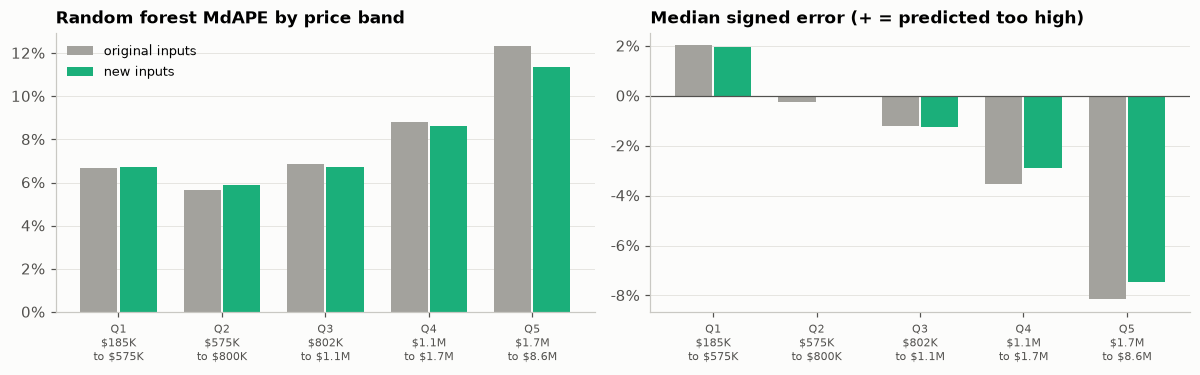

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
x = np.arange(5)
labels = [f'{q}\n' + r.replace('$', r'\$').replace(' to ', '\nto ') for q, r in zip(band.index, band['price range'])]
for k, (label, color) in enumerate([('original', '#a3a29d'), ('new', MODEL_COLORS['Random forest'])]):
    axes[0].bar(x + (k - 0.5) * 0.38, band[f'forest MdAPE, {label}'], width=0.36, color=color, label=f'{label} inputs')
    axes[1].bar(x + (k - 0.5) * 0.38, band[f'forest signed, {label}'], width=0.36, color=color, label=f'{label} inputs')
for ax in axes:
    ax.set_xticks(x, labels, fontsize=7.5)
    ax.grid(axis='x', visible=False)
axes[0].set_title('Random forest MdAPE by price band')
pct_axis(axes[0], 0)
axes[0].legend(frameon=False, fontsize=8.5)
axes[1].axhline(0, color='#52514e', lw=0.8)
axes[1].set_title('Median signed error (+ = predicted too high)')
pct_axis(axes[1], 0)
plt.tight_layout()
save_fig('05_error_by_band')
plt.show()

**Bias by month.** In Week 5 the forest priced homes too low in months when prices had risen relative to its training months, and too high when they had fallen, because it could not tell when a sale happened. With the month of sale as an input, this month-level bias should shrink.

In [19]:
bias = (stability[stability['model'] == 'Random forest']
        .pivot(index='eval_month', columns='feature set', values='median_signed_error')[[first, last]])
print(f'Average size of the monthly bias (mean of absolute median signed error): '
      f'original {bias[first].abs().mean():.2f}%, new {bias[last].abs().mean():.2f}%')
bias.round(2)

Average size of the monthly bias (mean of absolute median signed error): original 1.02%, new 0.87%


feature set,Original (Week 3),+ nearby sales price per sq ft
eval_month,,
2025-01,-0.27,-0.65
2025-02,-1.42,-1.77
2025-03,-1.57,-1.80
2025-04,-1.46,-1.38
2025-05,-1.06,-0.77
2025-06,-0.98,-0.56
2025-07,-0.13,0.18
2025-08,0.95,0.78
2025-09,1.06,0.80


## 9. Saved results

Written to `results/` (scores only, no property data), plus the chosen settings in `config/model_config_week6.json`.

In [20]:
validation.assign(evaluation='validation', eval_month=VALIDATION_MONTH).to_csv(
    RESULTS_DIR / '05_validation_by_feature_set.csv', index=False, float_format='%.6f')
if not followup.empty:
    followup.assign(evaluation='test, window follow-up', eval_month=TEST_MONTH).to_csv(
        RESULTS_DIR / '05_test_window_followup.csv', index=False, float_format='%.6f')
test_results.assign(evaluation='test', eval_month=TEST_MONTH, n_train_months=N_MONTHS).to_csv(
    RESULTS_DIR / '05_test_by_feature_set.csv', index=False, float_format='%.6f')
stability.to_csv(RESULTS_DIR / '05_stability_2025.csv', index=False, float_format='%.6f')
tuning.to_csv(RESULTS_DIR / '05_tuning_one_se.csv', index=False, float_format='%.6f')
pd.concat({m: t for m, (_, t) in window_tables.items()}, names=['model', 'window']).to_csv(
    RESULTS_DIR / '05_window_check.csv', float_format='%.6f')

model_config = {
    'random_seed': SEED,
    'n_train_months': N_MONTHS,
    'window_check_one_se_choice': WINDOW_CHOICE,
    'nearby_k': NEARBY_K,
    'feature_sets': feat.FEATURE_SETS,
    'chosen_settings': {f'{s} | {m}': {k: v for k, v in st.items()} for (s, m), st in chosen.items()},
    'selection_rule': 'one-standard-error rule, paired bootstrap over validation homes (2,000 resamples)',
    'school_districts': 'California School District Areas 2024-25 (CDE); demographic columns not used',
}
(ROOT / 'config' / 'model_config_week6.json').write_text(json.dumps(model_config, indent=2, default=str))
print('Saved results and config/model_config_week6.json')

Saved results and config/model_config_week6.json


## 10. Summary and next steps

**Old against new inputs on the test month** (April 2026, 12 training months, settings chosen per set with the one-standard-error rule):

| Model | MdAPE, original → new | R², original → new | MdAPE gain, 95% range | New inputs better in how many of 13 months |
|---|---:|---:|---:|---:|
| Linear regression | 11.38% → **9.50%** | 0.820 → 0.860 | 1.88 points (1.65 to 2.14) | 13 of 13 (mean gain 1.77) |
| Decision tree | 9.83% → **9.56%** | 0.844 → 0.862 | 0.27 points (0.02 to 0.52) | not checked |
| Random forest | 7.74% → **7.66%** | 0.884 → 0.890 | 0.08 points (−0.07 to 0.21) | 13 of 13 (mean gain 0.21) |

**What each step contributed.**
- Age at sale, bedroom-to-bathroom ratio, month of sale and school districts together improved the linear regression modestly (MdAPE 11.38% to 11.13%) and did not help the tree models (random forest 7.74% to 7.86%, within noise). Age carries almost the same information as year built, the bed/bath ratio can be formed by a tree from bedrooms and bathrooms, and the 686 school districts are coarser than the 1,567 ZIP codes the models already use.
- The nearby-sales price per square foot (median of the 100 nearest training sales, k chosen with the one-standard-error rule) produced almost all of the gain: about 1.6 points for the linear regression and 0.2 points for the random forest.

**Is the forest's gain real?** On the test month alone, its 95% range (−0.07 to 0.21 points) includes zero. Over all 13 evaluated months, though, the new inputs are better every month, by 0.05 to 0.34 points (mean 0.21). The gain is small but consistent.

**The training window now matters.** With the new inputs, longer windows help: on the January to March 2026 validation months, the forest's MdAPE falls from 7.59% at 12 months to 7.43% at 24 months (gap 0.16 points, standard error 0.04), and the one-standard-error rule picks 24 months for the forest and 18 for the linear regression. Scored once on the test month:
- **Random forest, new inputs, 24 months: MdAPE 7.40%, R² 0.900, MAE $148,862, 61.4% of homes within 10%**, the best result so far (Week 5: 7.76%, R² 0.885).
- Linear regression, new inputs, 18 months: MdAPE 9.45%, R² 0.864.

**Where it helps.** For the most expensive fifth of homes, the forest's MdAPE falls from 12.34% to 11.34% and its typical error from −8.2% to −7.5% (at 12 months); the cheaper bands are unchanged. The average size of the forest's month-to-month price-level bias falls from 1.02% to 0.87%. The bias does not disappear, because a tree cannot extend the month-of-sale trend beyond the months it was trained on.

**Settings.** The one-standard-error rule chose simpler models than the Week 5 search: random forest leaves of 2 homes instead of 1 for every input set, and for the original inputs a decision tree of depth 16 instead of 20. Test results for the original inputs barely changed (forest 7.74% against 7.76% in Week 5).

**Next steps (Week 7, gradient boosting)**
1. Train gradient-boosted trees (for example LightGBM or XGBoost) on the new input set, with light tuning of depth, learning rate and number of trees on the validation month, using the one-standard-error rule.
2. Use the 24-month window as the main configuration, keeping the 12-month results for comparison with earlier weeks.
3. Keep tracking the expensive fifth of homes and the month-level bias.